# APID 20 exploration (SWAP)

APID 20 carries the SWAP images. The README already knows the packet types (image packets, short "housekeeping"
packets), the 78 byte metadata block and the orientation flag, but not where the **pixel offsets** (the position of
the Sun in the image) are. This notebook takes every byte of APID 20 apart. Questions:

1. What kinds of packets are there, and what is in the "2 random bytes" of the short ones?
2. Is the packet header (time stamps) read right, and is the JPEG cut out of the packets right?
3. Is there anything hidden in the JPEG stream (markers, comments, padding)?
4. What is every byte of the metadata block? The PROBA2 Science Center publishes the level 0 FITS files made from these
   packets, so the metadata can be checked keyword by keyword against them.
5. Where do the sun center offsets come from, if not from APID 20?

**Short answer.** The 2 bytes are a CRC. The time stamps are the tick counter of the other APIDs, not days and
milliseconds. The continuation packets have an 8 byte header, not 14, and every packet ends in a CRC, so satdump's
JPEGs are slightly corrupt: fixed, every clean image decodes without a single warning. The JPEG stream holds nothing but
the image. All 92 bytes of the metadata now have a name: it is SWAP's on-board image header, and it has **no sun
center**. The level 0 archive files have none either (`CRPIX = 512.5`, `CRVAL` "unknown"). The calibration pipeline
finds the center by **fitting the limb in the image**, and section 10 does the same on our JPEGs, matching the
archive's level 1 sun centers to 0.1-0.2 pixel.

In [1]:
import binascii
import io
import itertools
import re
import shutil
import struct
import subprocess
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import UTC, datetime, timedelta
from pathlib import Path
from urllib.error import HTTPError
from urllib.request import Request, urlopen

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from PIL import Image, ImageFile

from cadu import iter_packets, packet_apid, packet_sequence_count

ImageFile.LOAD_TRUNCATED_IMAGES = True  # damaged images still give the rows before the damage

In [2]:
CADU_DIR = Path("cadus")
ARCHIVE_DIR = Path("swap_archive")  # level 0 / level 1 FITS from the PROBA2 Science Center, downloaded once
APID = 20

GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
GPS_MINUS_TICK = 1_209_613_891  # GPS seconds minus tick, from APID_0.ipynb / APID_18.ipynb
GPS_MINUS_UTC = 18  # leap seconds
FRACTION = 65536  # the 48 bit time stamps count 1/65536 of a tick

# Offsets into the payload (the packet minus its 6 byte primary header), big-endian
IMAGE_HEADER_LEN = 8  # 01, 32 bit tick, 16 bit fraction, 00: in every image packet
JPEG_OFFSET = 92  # FF D8 of the first packet of an image
CRC_LEN = 2
JPEG_SOI = b"\xff\xd8"

ROLL_COLORS = {0: "#2a78d6", 90: "#eb6834", 180: "#1baf7a", 270: "#eda100"}  # categorical slots 1-4
ROLL_MARKERS = {0: "o", 90: "s", 180: "^", 270: "D"}

## 1. Load

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
for path in sorted(CADU_DIR.glob("*.cadu")):
    packets += [(path.name, vcid, packet) for vcid, packet in iter_packets(path) if packet_apid(packet) == APID]

print(f"{len(packets)} packets with APID {APID} in {len({name for name, _, _ in packets})} dumps")
print("packet id:", Counter(packet[:2].hex() for _, _, packet in packets))
print("sequence flags:", Counter(packet[2] >> 6 for _, _, packet in packets))

4615 packets with APID 20 in 14 dumps
packet id: Counter({'0814': 4614, '2814': 1})
sequence flags: Counter({3: 4615})


## 2. Packet kinds, and the "2 random bytes"

The other APIDs end their packets with a CRC-16/CCITT (init `0xFFFF`). `binascii.crc_hqx(data, 0xFFFF)` is the same
CRC as the bitwise one in the other notebooks, only in C.

In [4]:
def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE, bit by bit as in the other notebooks."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


def crc_ok(packet: bytes) -> bool:
    return binascii.crc_hqx(packet[:-CRC_LEN], 0xFFFF) == int.from_bytes(packet[-CRC_LEN:])


assert all(crc16(p[:-2]) == binascii.crc_hqx(p[:-2], 0xFFFF) for _, _, p in packets if len(p) < 200)


def kind(packet: bytes) -> str:
    payload = packet[6:]
    if payload[0] == 0x01 and len(packet) > 200:
        return "image"
    if payload[:3] == b"\x10\x05\x01":
        return "PUS 5/1 event"
    if payload[:2] == b"\x10\x01":
        return f"PUS 1/{payload[2]} TC verification"
    return "other: " + payload[:3].hex()


census = pd.DataFrame(
    [(kind(p), vcid, len(p), crc_ok(p)) for _, vcid, p in packets], columns=["kind", "vc", "length", "crc_ok"]
)
summary = census.groupby("kind").agg(
    packets=("length", "size"),
    crc_ok=("crc_ok", "sum"),
    lengths=("length", lambda s: f"{s.min()}-{s.max()}" if s.nunique() > 1 else str(s.iloc[0])),
    virtual_channels=("vc", lambda s: dict(Counter(s))),
)
print(summary.to_string())

                         packets  crc_ok     lengths virtual_channels
kind                                                                 
PUS 1/1 TC verification       13      13          24     {1: 5, 2: 8}
PUS 1/7 TC verification       14      14          24     {1: 6, 2: 8}
PUS 5/1 event                367     367          22  {1: 38, 2: 329}
image                       4214    3760  1240-65536        {3: 4214}
other: 062db1                  1       0       21239           {3: 1}
other: 10023d                  1       0          24           {1: 1}
other: 274db6                  1       0        1678           {3: 1}
other: 918db6                  1       0       23752           {3: 1}
other: 9d407f                  1       0       13321           {3: 1}
other: cfbe8e                  1       0       43389           {3: 1}
other: f67856                  1       0       11505           {3: 1}


Every kind ends in a CRC-16 over the rest of the packet. The 22 byte packets the README calls housekeeping are PUS
**service 5 / subtype 1 event reports**, with the PUS layout of APIDs 2, 14, 18 and 22: `10 05 01`, the marker `00 01`,
a tick and its fraction, `00`, an event id `0x012c` (300), and **the "2 random bytes" are the CRC**, which all 367 pass.
So they are not the image offset. The 24 byte packets are telecommand verification reports, as in APIDs 8, 11, 14 and 17.
The `other` packets all fail the CRC: one is a 1/1 report with bit errors (`10 02 3d`), the six long ones on virtual
channel 3 are image packets whose first payload byte is damaged or that were glued together across lost frames.

In [5]:
events = [(name, vcid, p) for name, vcid, p in packets if kind(p) == "PUS 5/1 event"]
print(
    "offset:   0-5 primary | 6-8 PUS | 9-10 | 11-14 tick | 15-16 frac | 17 | 18-19 event id | 20-21 CRC | CRC computed"
)
for _, _, p in events[:5]:
    fields = [p[0:6], p[6:9], p[9:11], p[11:15], p[15:17], p[17:18], p[18:20], p[20:22]]
    print(" | ".join(f.hex(" ") for f in fields), f"| {crc16(p[:-2]):04x}")
print("event ids:", Counter(p[18:20].hex() for _, _, p in events), " byte 17:", Counter(p[17] for _, _, p in events))

telecommands = [(name, vcid, p) for name, vcid, p in packets if kind(p).startswith("PUS 1/")]
print("\nTC verification: request packet id", Counter(p[18:20].hex() for _, _, p in telecommands))
print("  -> 0x1814 = version 0, type 1 (telecommand), secondary header, APID 20: commands sent to SWAP")

offset:   0-5 primary | 6-8 PUS | 9-10 | 11-14 tick | 15-16 frac | 17 | 18-19 event id | 20-21 CRC | CRC computed
08 14 f5 76 00 0f | 10 05 01 | 00 01 | 0d f9 6a 46 | 66 40 | 00 | 01 2c | 24 ed | 24ed
08 14 f4 cc 00 0f | 10 05 01 | 00 01 | 0d f9 22 16 | 4a ac | 00 | 01 2c | d6 91 | d691
08 14 f4 cd 00 0f | 10 05 01 | 00 01 | 0d f9 22 84 | 4d 94 | 00 | 01 2c | 4d 69 | 4d69
08 14 f4 ce 00 0f | 10 05 01 | 00 01 | 0d f9 22 f2 | 4c 8c | 00 | 01 2c | 80 07 | 8007
08 14 f4 cf 00 0f | 10 05 01 | 00 01 | 0d f9 23 60 | 4b 2c | 00 | 01 2c | e0 c2 | e0c2
event ids: Counter({'012c': 367})  byte 17: Counter({0: 367})

TC verification: request packet id Counter({'1814': 27})
  -> 0x1814 = version 0, type 1 (telecommand), secondary header, APID 20: commands sent to SWAP


## 3. Image packets: header and time stamps

Here is the start of the payload of the first two packets of an image (the first one with `FF D8` at 92):

In [6]:
image_packets = [(name, vcid, p) for name, vcid, p in packets if kind(p) == "image"]
first_packets = [p for _, _, p in image_packets if p[6 + JPEG_OFFSET : 6 + JPEG_OFFSET + 2] == JPEG_SOI and crc_ok(p)]
example = first_packets[0]
following = next(
    p
    for _, _, p in image_packets
    if p[7:13] == example[7:13] and packet_sequence_count(p) == packet_sequence_count(example) + 1
)
for label, p in (("first", example), ("next", following)):
    payload = p[6:]
    print(f"{label:6s}", payload[:8].hex(" "), "|", payload[8:14].hex(" "), "|", payload[14:24].hex(" "), "...")

first  01 0d f9 23 ce 4d fc 00 | 0d f9 23 c0 68 88 | 00 0d f9 23 ce 4d fc 00 02 00 ...
next   01 0d f9 23 ce 4d fc 00 | 71 22 af c9 24 b8 | 7d f6 36 54 d1 c1 40 b5 17 61 ...


Byte 0 is `01` and bytes 1-6 are a **32 bit tick and a 16 bit fraction**, the tick counter of APIDs 0, 2, 18, 21 and 22
(one tick is a second, see APID 18), followed by `00`. The README (and satdump) read bytes 0-1 as a day count
(`0x010d`, which is just `01` and the top byte of the tick) and bytes 2-5 as milliseconds, which are really the low
3 bytes of the tick and the top byte of the fraction: tick x 256 + fraction / 256. Read as milliseconds that advances
**256 / 1000 = 0.256 s per second**, exactly the "SWAP clock runs slow by 0.256" of the APID 18 section. The image times
of `extract_images.py` are wrong for that reason, not because of a clock problem.

Every image packet starts with these 8 bytes, the same in all packets of one image. In the first packet, bytes 8-13
are a second, earlier time stamp; in the following ones they are already JPEG data (section 4).

In [7]:
def stamp(payload: bytes, offset: int) -> int:
    """48 bit time stamp: tick x 65536 + fraction."""
    return int.from_bytes(payload[offset : offset + 6])


def gps_time(ticks: float) -> datetime:
    return GPS_EPOCH + timedelta(seconds=ticks + GPS_MINUS_TICK)


def utc_time(ticks: float) -> datetime:
    return gps_time(ticks) - timedelta(seconds=GPS_MINUS_UTC)


old_ms = np.array(sorted({int.from_bytes(p[8:12]) for p in first_packets}))  # payload bytes 2-5, read as ms
new_ticks = np.array(sorted({stamp(p[6:], 1) / FRACTION for p in first_packets}))
ratio = np.diff(old_ms / 1000) / np.diff(new_ticks)
print(f"(change of the 'milliseconds' / 1000) / (change of the tick) over consecutive images: {np.median(ratio):.4f}")
print(f"images span {utc_time(new_ticks[0]):%Y-%m-%d} to {utc_time(new_ticks[-2]):%Y-%m-%d} (UTC, from the tick)")

(change of the 'milliseconds' / 1000) / (change of the tick) over consecutive images: 0.2560
images span 2025-08-07 to 2026-08-12 (UTC, from the tick)


### Images

The packets of an image share the 8 byte header. Should the same packet come twice (two dumps, two virtual channels),
the copy that passes the CRC is kept; in these dumps no image is in two of them.

In [8]:
def sequence_order(counts: list[int]) -> list[int]:
    """Sort 14 bit sequence counts, allowing for a wrap through 0."""
    counts = sorted(counts)
    if counts[-1] - counts[0] > 8192:
        counts.sort(key=lambda count: (count + 8192) % 16384)
    return counts


by_image: dict[int, dict[int, bytes]] = defaultdict(dict)  # end of acquisition stamp -> sequence count -> packet
dumps_of_image: dict[int, set[str]] = defaultdict(set)
for name, _, p in image_packets:
    key = stamp(p[6:], 1)
    copies = by_image[key]
    count = packet_sequence_count(p)
    dumps_of_image[key].add(name)
    if count not in copies or (crc_ok(p) and not crc_ok(copies[count])):
        copies[count] = p

images: dict[int, list[bytes]] = {}
for key, copies in by_image.items():
    images[key] = [copies[count] for count in sequence_order(list(copies))]


def has_first_packet(image: list[bytes]) -> bool:
    return image[0][6 + JPEG_OFFSET : 6 + JPEG_OFFSET + 2] == JPEG_SOI and crc_ok(image[0])


def is_clean(image: list[bytes]) -> bool:
    return has_first_packet(image) and len(image) == 12 and all(crc_ok(p) for p in image)


print(f"{len(images)} images (distinct time stamps), {sum(len(d) > 1 for d in dumps_of_image.values())} in two dumps")
print(f"  {sum(map(has_first_packet, images.values()))} with an intact first packet")
print(f"  {sum(map(is_clean, images.values()))} complete with all 12 packets passing the CRC ('clean' below)")
print("packets per image:", sorted(Counter(len(image) for image in images.values()).items()))

403 images (distinct time stamps), 0 in two dumps
  321 with an intact first packet
  225 complete with all 12 packets passing the CRC ('clean' below)
packets per image: [(1, 15), (2, 10), (3, 6), (4, 7), (5, 5), (6, 7), (7, 11), (8, 10), (9, 8), (10, 15), (11, 21), (12, 288)]


## 4. Cutting the JPEG out of the packets

satdump (and `extract_images.py`) skip 14 bytes of every packet and drop its last byte. With an 8 byte header in the
following packets and a 2 byte CRC at the end of all of them, that loses 6 JPEG bytes at the start of every following
packet and keeps one CRC byte at the end of every packet. The fix is to take bytes 8 to the CRC of every packet (92 in
the first one).

In [9]:
def satdump_jpeg(image: list[bytes]) -> bytes:
    return b"".join(p[6:][(JPEG_OFFSET if n == 0 else 14) : -1] for n, p in enumerate(image))


def jpeg_stream(image: list[bytes]) -> bytes:
    """The JPEG data of an image, plus the 0-15 bytes of padding after its end."""
    return b"".join(p[6:][(JPEG_OFFSET if n == 0 else IMAGE_HEADER_LEN) : -CRC_LEN] for n, p in enumerate(image))

Two independent checks of which one is right:

- **Restart markers.** The JPEG has a restart interval (section 5), so the entropy-coded data of every scan holds
  `FF D0` ... `FF D7` in cyclic order. Bytes lost or inserted in the data don't break that order by themselves, but they
  desynchronize the Huffman decoder until the next marker.
- **libjpeg's own warnings.** `djpeg` prints "Corrupt JPEG data" when the Huffman data of an interval doesn't add up.

In [10]:
DJPEG = shutil.which("djpeg")


def djpeg_warnings(jpeg: bytes) -> int | None:
    if DJPEG is None:
        return None
    result = subprocess.run([DJPEG, "-outfile", "/dev/null"], input=jpeg, capture_output=True, check=False)
    return result.stderr.decode().count("Corrupt JPEG data")


clean_keys = sorted(key for key, image in images.items() if is_clean(image))
warnings = pd.DataFrame(
    [(djpeg_warnings(satdump_jpeg(images[key])), djpeg_warnings(jpeg_stream(images[key]))) for key in clean_keys],
    columns=["satdump", "fixed"],
)
print(f"djpeg ({DJPEG}) warnings per image, {len(clean_keys)} clean images:")
print(warnings.apply(lambda column: column.value_counts()).fillna(0).astype(int).to_string())

djpeg (/usr/local/bin/djpeg) warnings per image, 225 clean images:
   satdump  fixed
0        0    225
1      225      0


2025-08-07 04:57:43: 2.9% of the pixels differ, up to 176 grey levels


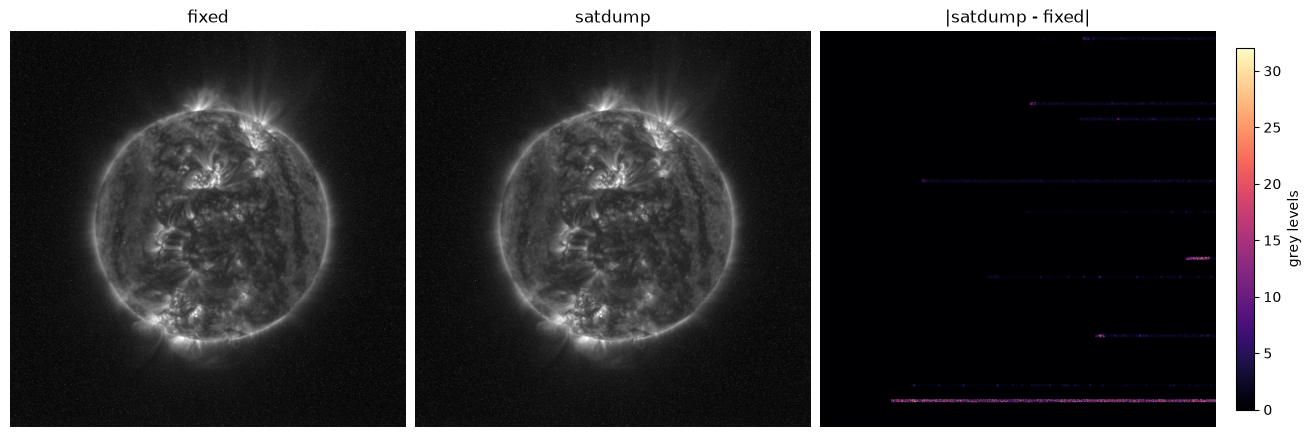

In [11]:
def decode(jpeg: bytes) -> np.ndarray:
    return np.array(Image.open(io.BytesIO(jpeg)).convert("L"), dtype=np.int16)


key = clean_keys[0]
old, new = decode(satdump_jpeg(images[key])), decode(jpeg_stream(images[key]))
changed = np.abs(old - new)
print(
    f"{utc_time(key / FRACTION):%Y-%m-%d %H:%M:%S}: {np.mean(changed > 0):.1%} of the pixels differ, "
    f"up to {changed.max()} grey levels"
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
axes[0].imshow(new, cmap="gray")
axes[0].set_title("fixed")
axes[1].imshow(old, cmap="gray")
axes[1].set_title("satdump")
shown = axes[2].imshow(changed, cmap="magma", vmax=max(4, np.percentile(changed[changed > 0], 99)))
axes[2].set_title("|satdump - fixed|")
fig.colorbar(shown, ax=axes[2], shrink=0.8, label="grey levels")
for axis in axes:
    axis.set_axis_off()
plt.show()

Every clean image decodes without a single warning when it is cut the right way, and with one when it is cut the satdump
way. The damage is a few percent of the pixels, in streaks of one block row: the decoder resynchronizes at the next
restart marker, and most of the lost bytes are in the late refinement scans of the progressive JPEG (section 5), which
is why the satdump images looked fine. `extract_images.py` should take `payload[8:-2]` of the following
packets and `payload[92:-2]` of the first.

## 5. The JPEG stream

All marker segments of an image, with the scans between them:

In [12]:
def segments(jpeg: bytes) -> list[tuple[str, int, bytes]]:
    """(marker, offset, segment body) of every marker segment, skipping the entropy-coded data of the scans."""
    out, position = [], 2  # after SOI
    while position < len(jpeg):
        marker = jpeg[position + 1]
        if marker == 0xD9:
            out.append(("EOI", position, b""))
            break
        length = int.from_bytes(jpeg[position + 2 : position + 4])
        out.append((f"FF{marker:02X}", position, jpeg[position + 4 : position + 2 + length]))
        position += 2 + length
        if marker == 0xDA:  # scan data: runs to the next marker that is not stuffing (FF 00) or a restart (FF D0-D7)
            while True:
                position = jpeg.index(b"\xff", position)
                if jpeg[position + 1] == 0 or 0xD0 <= jpeg[position + 1] <= 0xD7:
                    position += 2
                    continue
                break
    return out


NAMES = {"FFE0": "APP0", "FFDB": "DQT", "FFC2": "SOF2 progressive", "FFC4": "DHT", "FFDD": "DRI", "FFDA": "SOS"}
for marker, offset, body in segments(jpeg_stream(images[clean_keys[0]])):
    print(f"{offset:7d}  {marker} {NAMES.get(marker, ''):17s} {body[:24].hex(' ')}{' ...' if len(body) > 24 else ''}")

      2  FFE0 APP0              4a 46 49 46 00 01 01 00 00 01 00 01 00 00
     20  FFDB DQT               00 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 01 ...
     89  FFC2 SOF2 progressive  08 04 00 04 00 01 01 11 00
    102  FFC4 DHT               00 00 02 02 03 01 01 01 00 00 00 00 00 00 00 00 00 03 04 02 05 01 06 07 ...
    133  FFDD DRI               00 80
    139  FFDA SOS               01 01 00 00 00 01
  14327  FFC4 DHT               10 00 03 00 02 02 02 02 02 03 00 02 02 03 01 00 03 01 02 03 00 04 11 12 ...
  14375  FFDA SOS               01 01 00 01 05 02
  56366  FFC4 DHT               10 00 02 02 01 03 03 03 01 06 03 07 03 04 00 01 0d 01 02 03 11 12 13 21 ...
  56439  FFDA SOS               01 01 00 06 3f 02
 423159  FFC4 DHT               10 01 01 01 01 01 01 01 01 01 01 01 01 01 00 01 05 01 11 21 00 31 41 51 ...
 423199  FFDA SOS               01 01 00 01 3f 21
 584370  FFDA SOS               01 01 00 00 00 10
 586691  FFC4 DHT               10 01 0

In [13]:
structures = Counter(
    tuple((marker, body.hex()) for marker, _, body in segments(jpeg_stream(images[key])) if marker != "FFC4")
    for key in clean_keys
)
print(f"{len(structures)} distinct marker structure(s) (DHT left out) in {len(clean_keys)} clean images")
markers_found = Counter(marker for key in clean_keys for marker, _, _ in segments(jpeg_stream(images[key])))
print("markers:", dict(markers_found))

1 distinct marker structure(s) (DHT left out) in 225 clean images
markers: {'FFE0': 225, 'FFDB': 225, 'FFC2': 225, 'FFC4': 1125, 'FFDD': 225, 'FFDA': 1350, 'EOI': 225}


This is plain libjpeg output (`cjpeg -quality 100 -progressive -restart 1B` would make the same headers), the same in
every image:

- **APP0** is the standard JFIF header (version 1.1, no thumbnail). There is **no COM and no other APPn segment**.
- **DQT**: one table of 64 ones (quality 100); **SOF2**: progressive, 8 bit, 1024 x 1024, one component.
- **DRI**: a restart marker every 128 MCUs, i.e. every row of 8 x 8 blocks.
- **6 scans**, libjpeg's default progression for one component: DC (point transform 1), AC 1-5 and AC 6-63 (2), AC
  refinement 1-63 (2 -> 1), DC refinement, AC refinement (1 -> 0). The Huffman tables are optimized per scan.

So nothing is hidden in the JPEG headers. Behind the EOI:

In [14]:
tail_lengths, stale, size_rule = Counter(), Counter(), Counter()
for previous, key in itertools.pairwise(clean_keys):
    data, metadata = jpeg_stream(images[key]), images[key][0][6 : JPEG_OFFSET + 6]
    jpeg_length = int.from_bytes(metadata[88:92])
    size_rule[
        (data[jpeg_length - 2 : jpeg_length] == b"\xff\xd9", int.from_bytes(metadata[76:80]) == len(data) + 4)
    ] += 1
    tail = data[jpeg_length:]
    tail_lengths[len(tail)] += 1
    if tail:
        stale[tail == jpeg_stream(images[previous])[jpeg_length : jpeg_length + len(tail)]] += 1

print("(EOI ends at metadata 88-91, metadata 76-79 = stream length + 4):", dict(size_rule))
print("bytes after the EOI:", sorted(tail_lengths.items()))
print("...equal to the bytes at the same place in the previous clean image:", dict(stale))

(EOI ends at metadata 88-91, metadata 76-79 = stream length + 4): {(True, True): 224}
bytes after the EOI: [(0, 13), (1, 8), (2, 11), (3, 12), (4, 16), (5, 18), (6, 8), (7, 14), (8, 16), (9, 13), (10, 14), (11, 16), (12, 20), (13, 17), (14, 10), (15, 18)]
...equal to the bytes at the same place in the previous clean image: {False: 185, True: 26}


Metadata 88-91 is the exact length of the JPEG (SOI to EOI), and the stream in the packets is that, plus 0-15 bytes up to
a multiple of 16 (with the 4 bytes of 88-91 in front). The padding is whatever was in the buffer: often the bytes of the
image before. **The JPEG stream holds the image and nothing else.**

## 6. The metadata block, keyword by keyword

First, which of the 92 bytes change at all, over the first packets that pass the CRC:

In [15]:
first_payloads = {key: image[0][6 : JPEG_OFFSET + 6] for key, image in images.items() if has_first_packet(image)}
matrix = np.array([np.frombuffer(m, dtype=np.uint8) for m in first_payloads.values()])
distinct = [len(set(matrix[:, offset])) for offset in range(JPEG_OFFSET)]
print(f"{len(matrix)} first packets")
print("offsets with more than one value:", [offset for offset, n in enumerate(distinct) if n > 1])
print("the constant bytes:", {o: f"{matrix[0, o]:02x}" for o, n in enumerate(distinct) if n == 1 and matrix[0, o]})

321 first packets
offsets with more than one value: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 23, 24, 25, 26, 27, 28, 29, 30, 75, 78, 79, 90, 91]
the constant bytes: {0: '01', 22: '02', 47: '01', 51: '0a', 54: '03', 55: 'ff', 58: '03', 59: 'ff', 60: '3b', 64: '04', 65: '0b', 66: '01', 67: '01', 68: '0e', 69: '10', 71: '0a', 73: '01', 77: '0b', 89: '0b'}


The PROBA2 Science Center keeps a level 0 FITS file for every SWAP image
(`https://proba2.sidc.be/swap/level0/YYYY/MM/DD/swap_lv0_YYYYMMDD_HHMMSS.fits`), made on the ground from these
packets. Its header has keywords whose values are exactly the "unknown" bytes: `LANG_ROT = 0.7071067819` (offset 23),
`PGA_OFFS = 59` (`3b`), `HASBLACK = 4`, `HASOFFST = 11` (`04 0b`), `RECNUM = 3600` (`0e 10`), `PN` and `SIZCOMPI`.
To check them one by one, each of our images is matched to its archive file: the file names are the time of
observation, so the 9 nearest files are candidates, and the one with the same `SIZCOMPI` (a 6 digit number that differs
for every image) and `PN` is it. Only the header of a level 0 file is downloaded (an HTTP range request); they are cached
in `swap_archive/`.

In [16]:
ARCHIVE = "https://proba2.sidc.be/swap"
LEVEL0_URL = ARCHIVE + "/level0/{d}/swap_lv0_{name}.fits"
LEVEL1_URL = ARCHIVE + "/data/bsd/{d}/swap_lv1_{name}.fits"
HEADER_BYTES = 17280  # 6 FITS blocks, more than the headers need


def day_path(name: str) -> str:
    return f"{name[:4]}/{name[4:6]}/{name[6:8]}"


def archive_names(day: datetime) -> list[str]:
    """The level 0 file names (YYYYMMDD_HHMMSS) of a day."""
    cache = ARCHIVE_DIR / "listings" / f"{day:%Y%m%d}.txt"
    if not cache.exists():
        cache.parent.mkdir(parents=True, exist_ok=True)
        with urlopen(f"{ARCHIVE}/level0/{day:%Y/%m/%d}/", timeout=60) as response:
            html = response.read().decode()
        cache.write_text("\n".join(sorted(set(re.findall(r"swap_lv0_(\d{8}_\d{6})\.fits", html)))))
    return cache.read_text().split()


def archive_header(name: str, level: int) -> fits.Header | None:
    """The FITS header of a level 0 or 1 file (None if the archive doesn't have it)."""
    cache = ARCHIVE_DIR / f"lv{level}_headers" / f"{name}.hdr"
    if not cache.exists():
        cache.parent.mkdir(parents=True, exist_ok=True)
        url = (LEVEL0_URL if level == 0 else LEVEL1_URL).format(d=day_path(name), name=name)
        try:
            with urlopen(Request(url, headers={"Range": f"bytes=0-{HEADER_BYTES - 1}"}), timeout=60) as response:
                cache.write_bytes(response.read())
        except HTTPError:
            cache.write_bytes(b"")
    raw = cache.read_bytes()
    if not raw.startswith(b"SIMPLE"):
        return None
    end = raw.index(b"END" + b" " * 77)
    return fits.Header.fromstring(raw[: end + 80].decode("ascii"))


def match(key: int) -> tuple[int, str | None]:
    """The level 0 file of an image: same compressed size and priority, among the files nearest in time."""
    metadata = first_payloads[key]
    start = utc_time(stamp(metadata, 8) / FRACTION)
    if start.year > 2030:  # time stamp with bit errors
        return key, None
    names = [n for day in (start - timedelta(days=1), start, start + timedelta(days=1)) for n in archive_names(day)]
    names.sort(key=lambda n: abs((datetime.strptime(n, "%Y%m%d_%H%M%S").replace(tzinfo=UTC) - start).total_seconds()))
    for name in names[:9]:
        header = archive_header(name, 0)
        if header and header["SIZCOMPI"] == int.from_bytes(metadata[76:80]) and header["PN"] == metadata[75]:
            return key, name
    return key, None


for day in {utc_time(stamp(m, 8) / FRACTION).date() for m in first_payloads.values()}:  # listings first, one by one
    if day.year < 2030:
        for d in (day - timedelta(days=1), day, day + timedelta(days=1)):
            archive_names(datetime(d.year, d.month, d.day, tzinfo=UTC))
with ThreadPoolExecutor(8) as pool:
    archive_name = {key: name for key, name in pool.map(match, sorted(first_payloads)) if name}
level0 = {key: archive_header(name, 0) for key, name in archive_name.items()}
print(
    f"{len(archive_name)} of {len(first_payloads)} images have their level 0 file, {len(set(archive_name.values()))}"
)
print("distinct files; the others are not in the archive (or their time stamp has bit errors)")

294 of 321 images have their level 0 file, 294
distinct files; the others are not in the archive (or their time stamp has bit errors)


Which archive keywords change over these images, and which of them are about SWAP rather than the spacecraft:

In [17]:
varying = {}
for keyword in level0[next(iter(level0))]:
    if keyword in ("COMMENT", "HISTORY", ""):
        continue
    values = {str(h.get(keyword)) for h in level0.values()}
    if len(values) > 1:
        varying[keyword] = len(values)
print(varying)

{'FILENAME': 294, 'FILE_TMR': 294, 'FILE_RAW': 294, 'FILE_TAR': 14, 'DATE': 294, 'DATE-OBS': 294, 'CD1_1': 3, 'CD1_2': 3, 'CD2_1': 3, 'CD2_2': 3, 'CROTA1': 4, 'CROTA2': 4, 'DTPLAR1': 96, 'DTPLAR2': 103, 'P2_X0': 294, 'P2_Y0': 294, 'P2_ROLL': 294, 'SOLAR_EP': 294, 'HGLT_OBS': 294, 'HGLN_OBS': 294, 'RSUN_ARC': 294, 'DSUN_OBS': 294, 'HEEX_OBS': 294, 'HEEY_OBS': 294, 'HEEZ_OBS': 294, 'GSEX_OBS': 294, 'GSEY_OBS': 294, 'GSEZ_OBS': 294, 'LOS_ALT': 152, 'TRAPPROT': 21, 'TRAPELEC': 94, 'GEOD_ALT': 294, 'GEOD_LAT': 294, 'GEOD_LON': 294, 'TEMP1DET': 21, 'TEMP2DET': 21, 'TTEMP1': 294, 'TTEMP2': 294, 'TRANTIME': 294, 'SACQTIME': 294, 'EACQTIME': 294, 'LANG_ROT': 4, 'PN': 7, 'SIZCOMPI': 251, 'CHECKSUM': 294, 'DATASUM': 294}


Apart from the file names, dates and checksums, the keywords that change are the attitude (`P2_X0`, `P2_Y0`,
`P2_ROLL`, the CD matrix, `CROTA`), the orbit (`*_OBS`, `GEOD_*`, `LOS_ALT`, radiation models), the detector temperature
with its sample times, `DTPLAR*` (time to the previous and next rotation), and from SWAP itself only the three OBET time
stamps, `LANG_ROT`, `PN` and `SIZCOMPI`. Exactly the bytes that change in the metadata. Now byte by byte:

In [18]:
def u(metadata: bytes, offset: int, size: int) -> int:
    return int.from_bytes(metadata[offset : offset + size])


def f64(metadata: bytes, offset: int) -> float:
    return struct.unpack(">d", metadata[offset : offset + 8])[0]


def obet(metadata: bytes, offset: int) -> int:
    """A 48 bit time stamp in the unit of the archive's OBET counts (1/16384 tick, with bit 42 set)."""
    return stamp(metadata, offset) // 4 + 2**42


# Enumerations as the comments of the level 0 keywords list them
OBS_MODES = ["Sun centered", "Fixed off-pointing", "Variable off-pointing", "CME tracking"]  # sun_cen, fix_off, ...
CAP_MODES = ["DS", "CDS"]
ARTEFX = ["off", "on", "cosmic rays"]
RECODING = ["off", "fixed", "adaptive"]

FIELDS = [  # offset(s), keyword, decoded from the packet, value in the header -> comparable values
    ("1-6", "EACQTIME", lambda m: obet(m, 1), lambda h: h["EACQTIME"]),
    ("8-13", "SACQTIME", lambda m: obet(m, 8), lambda h: h["SACQTIME"]),
    ("15-20", "TRANTIME", lambda m: obet(m, 15), lambda h: h["TRANTIME"]),
    ("22", "OBS_MODE", lambda m: OBS_MODES[m[22]], lambda h: h["OBS_MODE"]),
    ("23-30", "LANG_ROT", lambda m: round(f64(m, 23), 10), lambda h: round(h["LANG_ROT"], 10)),
    ("31-38", "PAV_ROT0", lambda m: f64(m, 31), lambda h: h["PAV_ROT0"]),
    ("39-46", "PAV_ROT1", lambda m: f64(m, 39), lambda h: h["PAV_ROT1"]),
    ("47", "CAP_MODE", lambda m: CAP_MODES[m[47]], lambda h: h["CAP_MODE"]),
    ("48-51", "EXPTIME", lambda m: u(m, 48, 4), lambda h: h["EXPTIME"]),
    ("52-53", "FIRSTROW", lambda m: u(m, 52, 2) + 1, lambda h: h["FIRSTROW"]),
    ("54-55", "LAST_ROW", lambda m: u(m, 54, 2) + 1, lambda h: h["LAST_ROW"]),
    ("56-57", "FIRSTCOL", lambda m: u(m, 56, 2) + 1, lambda h: h["FIRSTCOL"]),
    ("58-59", "LAST_COL", lambda m: u(m, 58, 2) + 1, lambda h: h["LAST_COL"]),
    ("60", "PGA_OFFS", lambda m: m[60], lambda h: h["PGA_OFFS"]),
    ("64", "HASBLACK", lambda m: m[64], lambda h: h["HASBLACK"]),
    ("65", "HASOFFST", lambda m: m[65], lambda h: h["HASOFFST"]),
    ("66", "ARTEFX", lambda m: ARTEFX[m[66]], lambda h: h["ARTEFX"]),
    ("67", "RECODING", lambda m: RECODING[m[67]], lambda h: h["RECODING"]),
    ("68-69", "RECNUM", lambda m: u(m, 68, 2), lambda h: h["RECNUM"]),
    ("70-71", "RECBIAS", lambda m: u(m, 70, 2), lambda h: h["RECBIAS"]),
    ("74", "LZWDECOR", lambda m: ["off", "on"][m[74]], lambda h: h["LZWDECOR"]),
    ("75", "PN", lambda m: m[75], lambda h: h["PN"]),
    ("76-79", "SIZCOMPI", lambda m: u(m, 76, 4), lambda h: h["SIZCOMPI"]),
    ("80-83", "NPRESCR", lambda m: u(m, 80, 4), lambda h: h["NPRESCR"]),
    ("84-87", "NPRESLZW", lambda m: u(m, 84, 4), lambda h: h["NPRESLZW"]),
]

rows = []
for offsets, keyword, from_packet, from_header in FIELDS:
    pairs = [(from_packet(first_payloads[key]), from_header(header)) for key, header in level0.items()]
    rows.append(
        {
            "offset": offsets,
            "keyword": keyword,
            "comment": level0[next(iter(level0))].comments[keyword].strip(),
            "agree": f"{sum(a == b for a, b in pairs)} / {len(pairs)}",
            "distinct values": len({b for _, b in pairs}),
            "example": pairs[0][1],
        }
    )
with pd.option_context("display.max_colwidth", 60, "display.width", 200):
    print(pd.DataFrame(rows).to_string(index=False))

offset  keyword                                        comment     agree  distinct values               example
   1-6 EACQTIME               [ct] OBET end   acquisition time 294 / 294              294         8149392530490
  8-13 SACQTIME               [ct] OBET start acquisition time 294 / 294              294         8149392302728
 15-20 TRANTIME                    [ct] OBET transferring time 294 / 294              294         8149392530490
    22 OBS_MODE           sun_cen, fix_off, var_off, cme_track 294 / 294                1 Variable off-pointing
 23-30 LANG_ROT       commanded large angle rotation component 294 / 294                4                   0.0
 31-38 PAV_ROT0          commanded paving rotation component 0 294 / 294                1                   0.0
 39-46 PAV_ROT1          commanded paving rotation component 1 294 / 294                1                   0.0
    47 CAP_MODE                          (DS,CDS) capture mode 294 / 294                1               

**Every field agrees in every matched image.** The ones that vary (the 3 time stamps, `LANG_ROT`, `PN`, `SIZCOMPI`)
prove the offsets. For the constant ones the value fits and the order is the order of the keywords in the FITS header,
but which byte is which among equal values (the enumerations, 52-59 as four 16 bit numbers rather than two 32 bit
ones) cannot be proven with constant data. Left over:

| Offset | Bytes | Probably |
|---|---|---|
| 0, 7, 14, 21 | `01`, `00`, `00`, `00` | framing of the three time stamps |
| 61-63 | `00 00 00` | `PGA_GAIN` (1, coded as 0?), `LED_POW` (off), `LED_SEL` (a); `HASSTDBY`, `READRDIV` (0) have to be somewhere too |
| 72-73 | `00 01` | `COMPRESS` (jpeg) and/or `REBIN` (off) |
| 88-91 | | length of the JPEG (section 5), not a FITS keyword |

So the metadata is SWAP's on-board image header, and the level 0 files are made of it plus spacecraft data. Notes:

- **Time stamps.** The archive's OBET counts are our 48 bit stamps / 4 + 2^42, exactly, for all three. Bytes 8-13 are the
  **start of acquisition** and 1-6 (= 15-20) the end: on average 13.9 s apart for an exposure of 10 s (`EXPTIME`,
  48-51).
- **`LANG_ROT`** is the "commanded large angle rotation component" (23-30), with `PAV_ROT0/1`, the paving (off-pointing)
  rotation components (31-46), zero in all our images. `OBS_MODE` is "Variable off-pointing" all the same.
- **Detector offsets.** `PGA_OFFS = 59` (the analogue offset of the amplifier), `HASBLACK = 4` and `HASOFFST = 11`
  (black and offset level of the HAS detector) are the electronic offsets of the detector. If "pixel offsets" means the
  bias of the pixel values, these are them; they never changed in the 2 months of dumps.
- **Recoding.** `RECODING = fixed`, `RECBIAS = 10`, `RECNUM = 3600`: the detector values are mapped to 8 bits on board
  before the JPEG compression (section 9).
- **`PN`**, the "on-board priority number" (75): 100-130 in patterns (runs of 130, alternating 110 / 120), probably
  what decides which images are kept for downlink. Not related to the image.

## 7. Time

`DATE-OBS` in the archive is the UTC of the start of acquisition, converted with the ground's clock correlation. Against
the GPS offset of APID 18 (one constant for all dumps):

In [19]:
times = pd.DataFrame(
    {
        "start": [stamp(first_payloads[key], 8) / FRACTION for key in level0],
        "end": [stamp(first_payloads[key], 1) / FRACTION for key in level0],
        "date_obs": [datetime.fromisoformat(h["DATE-OBS"]).replace(tzinfo=UTC) for h in level0.values()],
    }
)
times["day"] = [utc_time(t).date() for t in times["start"]]
for column in ("start", "end"):
    times[f"date_obs - {column}"] = [
        (d - utc_time(t)).total_seconds() for d, t in zip(times["date_obs"], times[column], strict=True)
    ]


def scatter_within_days(column: str) -> float:
    """rms of the residual of a straight line per day: how well a column predicts DATE-OBS."""
    residuals = []
    for _, day in times.groupby("day"):
        if len(day) >= 5:
            fit = np.polyfit(day["start"], day[column], 1)
            residuals += list(day[column] - np.polyval(fit, day["start"]))
    return float(np.sqrt(np.mean(np.square(residuals))))


print(f"acquisition takes {np.median(times['end'] - times['start']):.2f} s (median)")
for column in ("start", "end"):
    print(
        f"DATE-OBS - UTC of the {column:5s}: rms within a day "
        f"{scatter_within_days(f'date_obs - {column}') * 1000:.1f} ms"
    )
print(times.groupby("day")["date_obs - start"].agg(["size", "mean", "min", "max"]).round(2).to_string())

acquisition takes 13.94 s (median)
DATE-OBS - UTC of the start: rms within a day 2.2 ms
DATE-OBS - UTC of the end  : rms within a day 22.2 ms
            size    mean     min     max
day                                     
2025-08-07    12  -11.08  -11.10  -11.05
2025-08-08    27  -10.12  -10.16  -10.09
2025-08-09     1   -9.02   -9.02   -9.02
2025-08-10    28   -8.00   -8.03   -7.97
2025-08-14    33   -3.18   -3.19   -3.11
2025-08-16    29   -1.43   -1.62   -1.19
2025-08-17    21   -0.50   -0.53   -0.47
2025-08-18    21    0.67    0.50    0.89
2025-08-19    23    1.63    1.60    1.66
2025-08-20     9    2.64    2.63    2.67
2025-08-21     8    4.13    4.12    4.15
2025-08-22     4    5.20    5.20    5.21
2025-08-23    36    5.99    5.86    6.52
2025-10-09    19   56.40   56.16   56.69
2025-10-10    16   56.78   56.70   56.87
2026-08-12     7  382.98  382.95  383.01


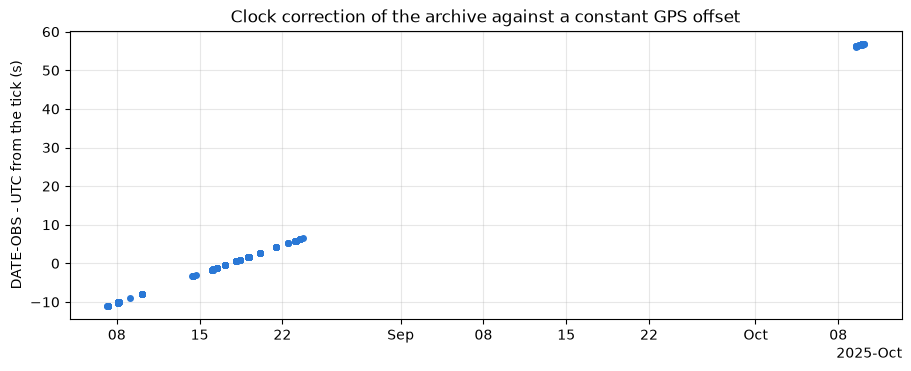

In [20]:
fig, axis = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
shown = times[times["date_obs"].dt.year == 2025]  # the eclipse dump (2026-08-12, +383 s) is left out of the plot
axis.plot(shown["date_obs"], shown["date_obs - start"], "o", ms=4, color="#2a78d6")
axis.xaxis.set_major_formatter(mdates.ConciseDateFormatter(axis.xaxis.get_major_locator()))
axis.set_ylabel("DATE-OBS - UTC from the tick (s)")
axis.set_title("Clock correction of the archive against a constant GPS offset")
axis.grid(alpha=0.3)
plt.show()

`DATE-OBS` follows the start of acquisition to 2 ms within a day, ten times better than the end. The offset against the constant GPS
offset drifts by about 1.1 s per day (-11 s on August 7 to +6 s on August 23, +57 s in October, +383 s on 2026-08-12):
the on-board tick does not run at one GPS second per tick in the long run, so a GPS offset needs to be fitted per dump
(from APID 18), and the archive matching above has to search a few files around the estimate.

## 8. Event reports and telecommands

The event reports, against the end of acquisition of all images we have (from any of their packets):

In [21]:
image_ends = np.array(sorted(images)) / FRACTION
event_ticks = np.array(sorted({stamp(p[6:], 5) for _, _, p in events})) / FRACTION
gaps = np.diff(event_ticks)
nearest = np.array([image_ends[np.argmin(np.abs(image_ends - t))] for t in event_ticks])
print(f"{len(event_ticks)} events; spacing (s):", Counter(np.round(gaps).astype(int)).most_common(3))
offset_ms = (event_ticks - nearest) * 1000
print(
    f"{np.sum(np.abs(offset_ms) < 1000)} events have an image of ours within 1 s; "
    "their delay after the end of acquisition:"
)
print("  ", Counter(np.round(offset_ms[np.abs(offset_ms) < 1000], 2)).most_common(4), "ms")
phase = np.round((event_ticks - nearest) / 110, 3)
print("the others are a multiple of 110 s away from one:", Counter(phase[np.abs(offset_ms) >= 1000]).most_common(6))

367 events; spacing (s): [(np.int64(110), 342), (np.int64(18), 11), (np.int64(83160), 2)]
79 events have an image of ours within 1 s; their delay after the end of acquisition:
   [(np.float64(0.12), 52), (np.float64(0.18), 27)] ms
the others are a multiple of 110 s away from one: [(np.float64(1.0), 38), (np.float64(-1.0), 37), (np.float64(-2.0), 20), (np.float64(-4.0), 19), (np.float64(-3.0), 19), (np.float64(2.0), 19)]


Event 300 is sent 0.1-0.2 ms after **every** image is taken, every 110 s (the 18 s gaps are in the eclipse dump, which
had a faster cadence). Only about a fifth of the images it reports are in our dumps: the rest are taken but not downlinked
in these passes. So the events are a log of the image times, nothing more; they don't have room for anything else.

The telecommands to SWAP (APID 20 as the request packet id):

In [22]:
for name, vcid, p in telecommands:
    tick = stamp(p[6:], 5) / FRACTION
    nearest_end = image_ends[np.argmin(np.abs(image_ends - tick))]
    print(
        f"{name:34s} vc {vcid}  1/{p[8]}  {gps_time(tick):%Y-%m-%d %H:%M:%S} GPS  seq {p[20:22].hex()}  "
        f"nearest image end {tick - nearest_end:+9.1f} s  CRC {'ok' if crc_ok(p) else 'bad'}"
    )

proba2_dump(1).cadu                vc 1  1/1  2025-10-09 16:42:59 GPS  seq d3a1  nearest image end   -6370.0 s  CRC ok
proba2_dump(1).cadu                vc 1  1/7  2025-10-09 16:42:59 GPS  seq d3a1  nearest image end   -6370.0 s  CRC ok
proba2_dump(1).cadu                vc 2  1/1  2025-10-09 11:34:40 GPS  seq d3a0  nearest image end    -449.0 s  CRC ok
proba2_dump(1).cadu                vc 2  1/7  2025-10-09 11:34:40 GPS  seq d3a0  nearest image end    -449.0 s  CRC ok
proba2_dump(1).cadu                vc 2  1/1  2025-10-09 11:41:56 GPS  seq d397  nearest image end     -13.0 s  CRC ok
proba2_dump(1).cadu                vc 2  1/7  2025-10-09 11:41:56 GPS  seq d397  nearest image end     -13.0 s  CRC ok
proba2_dump(10).cadu               vc 2  1/1  2025-08-14 15:04:22 GPS  seq d09c  nearest image end    -653.0 s  CRC ok
proba2_dump(10).cadu               vc 2  1/7  2025-08-14 15:04:22 GPS  seq d09c  nearest image end    -653.0 s  CRC ok
proba2_dump(10).cadu               vc 2  1/1  20

One or two commands per dump, accepted and completed within 1 ms, at no fixed time against the images. Their content
isn't in the downlink.

## 9. Pixel values: from JPEG grey levels to detector numbers

The level 0 image is 16 bit with values 10 to 3588 (DN), our JPEG 8 bit. Ten full level 0 files (2 MB each) of clean
images give the mapping:

In [23]:
FULL_DIR = ARCHIVE_DIR / "lv0"
with_file = [key for key in clean_keys if key in archive_name]
samples = with_file[:: len(with_file) // 10][:10]  # spread over the dumps
pairs = defaultdict(Counter)  # grey level -> DN -> pixels
orientation_r = defaultdict(list)
for key in samples:
    path = FULL_DIR / f"swap_lv0_{archive_name[key]}.fits"
    if not path.exists():
        FULL_DIR.mkdir(parents=True, exist_ok=True)
        with urlopen(
            LEVEL0_URL.format(d=day_path(archive_name[key]), name=archive_name[key]), timeout=120
        ) as response:
            path.write_bytes(response.read())
    dn = fits.getdata(path).astype(np.int32)
    grey = decode(jpeg_stream(images[key])).astype(np.int32)
    for label, candidate in (
        ("as is", grey),
        ("flipped up-down", grey[::-1]),
        ("flipped left-right", grey[:, ::-1]),
        ("rotated 180", grey[::-1, ::-1]),
        ("transposed", grey.T),
    ):
        orientation_r[label].append(np.corrcoef(np.sqrt(dn).ravel(), candidate.ravel())[0, 1])
    flipped = grey[::-1]
    for level in np.unique(flipped):
        values, counts = np.unique(dn[flipped == level], return_counts=True)
        pairs[int(level)].update(dict(zip(values.tolist(), counts.tolist(), strict=True)))

print(
    "correlation of sqrt(level 0) with the JPEG:", {k: round(float(np.mean(v)), 4) for k, v in orientation_r.items()}
)
RECODE_TABLE = np.array([pairs[level].most_common(1)[0][0] for level in range(256)])
on_table = sum(pairs[level][RECODE_TABLE[level]] for level in range(256)) / sum(
    sum(c.values()) for c in pairs.values()
)
print(f"{on_table:.2%} of the pixels have the DN of the table for their grey level (the rest are 1 grey level off)")
print("table (DN of grey level 0..255):", RECODE_TABLE.tolist())

correlation of sqrt(level 0) with the JPEG: {'as is': 0.7053, 'flipped up-down': 0.9975, 'flipped left-right': 0.6939, 'rotated 180': 0.7191, 'transposed': 0.6193}
98.73% of the pixels have the DN of the table for their grey level (the rest are 1 grey level off)
table (DN of grey level 0..255): [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 29, 32, 35, 38, 41, 44, 47, 50, 53, 56, 59, 62, 65, 68, 71, 74, 77, 80, 84, 89, 94, 99, 104, 109, 114, 119, 124, 129, 134, 139, 144, 149, 154, 159, 164, 169, 174, 179, 185, 192, 199, 206, 213, 220, 227, 234, 241, 248, 255, 262, 269, 276, 283, 291, 300, 309, 318, 327, 336, 345, 354, 363, 372, 381, 390, 399, 408, 417, 426, 435, 444, 453, 462, 471, 480, 490, 501, 512, 523, 534, 545, 556, 567, 578, 589, 600, 611, 622, 633, 644, 656, 669, 682, 695, 708, 721, 734, 747, 760, 773, 786, 799, 812, 825, 838, 851, 864, 877, 890, 903, 916, 930, 945, 960, 975, 990, 1005, 1020, 1035, 1050, 1065, 1080, 1095, 1110, 1125, 1140, 1155, 1170, 1

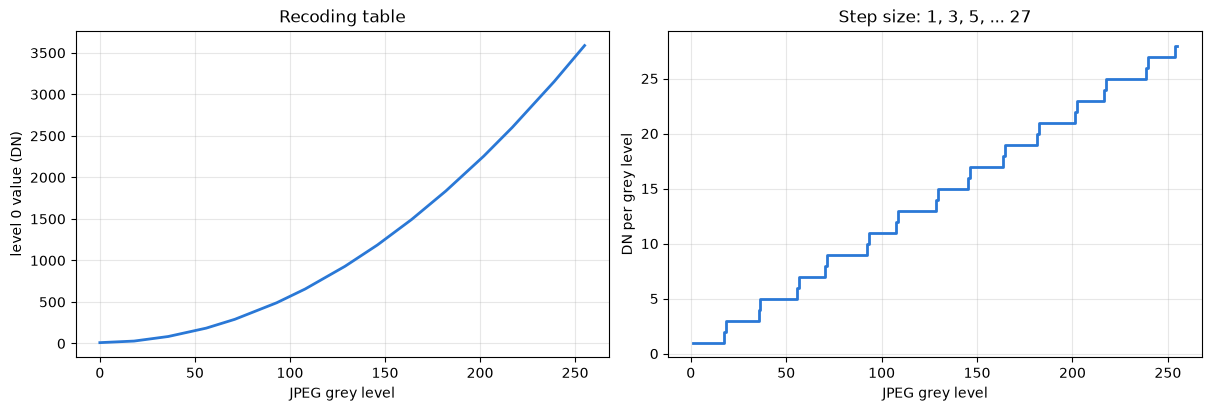

run lengths of each step size: [(1, 17), (2, 1), (3, 17), (4, 1), (5, 19), (6, 1), (7, 14), (8, 1), (9, 21), (10, 1), (11, 14), (12, 1), (13, 20), (14, 1), (15, 16), (16, 1), (17, 17), (18, 1), (19, 17), (20, 1), (21, 19), (22, 1), (23, 14), (24, 1), (25, 21), (26, 1), (27, 14), (28, 2)]


In [24]:
steps = np.diff(RECODE_TABLE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(np.arange(256), RECODE_TABLE, color="#2a78d6", lw=2)
axes[0].set_xlabel("JPEG grey level")
axes[0].set_ylabel("level 0 value (DN)")
axes[0].set_title("Recoding table")
axes[1].step(np.arange(1, 256), steps, where="mid", color="#2a78d6", lw=2)
axes[1].set_xlabel("JPEG grey level")
axes[1].set_ylabel("DN per grey level")
axes[1].set_title("Step size: 1, 3, 5, ... 27")
for axis in axes:
    axis.grid(alpha=0.3)
plt.show()
print(
    "run lengths of each step size:",
    [(int(s), int(n)) for s, n in zip(*np.unique(steps, return_counts=True), strict=True)],
)

- The level 0 array is our JPEG **flipped up-down** (FITS row 1 is the last JPEG row).
- The mapping is a fixed table, not a formula: grey level 0 is DN 10 (`RECBIAS`), 255 is DN 3588 (`DATAMAX`, just
  below `RECNUM = 3600`), and the DN per grey level grows in odd steps 1, 3, 5 ... 27, with a half step at each change.
  That is a piecewise linear square root (bins as wide as the shot noise), reconstructed at the bin centres. 98.7 % of
  the pixels sit exactly on the table; the rest are 1 grey level away because the ground decoder rounds its IDCT a
  little differently from Pillow's.
- So `RECODE_TABLE[np.flipud(jpeg)]` is the level 0 image in DN, ready for the dark subtraction of the pipeline.

## 10. The sun center

### What the archive and the pipeline do

The level 0 headers have no sun center: `CRPIX1/2 = 512.5` and `CRVAL1/2 = 0` ("level < 1: unknown") in every file. The
rotation comes from the spacecraft roll `P2_ROLL` (through the CD matrix), and `LANG_ROT` is its commanded value:

In [25]:
def nearest_roll(degrees: float) -> int:
    return int(round(degrees / 90) * 90 % 360)


roll_table = pd.DataFrame(
    {
        "LANG_ROT": [round(f64(first_payloads[key], 23), 4) for key in level0],
        "P2_ROLL": [nearest_roll(h["P2_ROLL"]) for h in level0.values()],
        "CROTA1": [h["CROTA1"] for h in level0.values()],
    }
)
print(roll_table.value_counts().sort_index().to_string())
print(
    "CRPIX:",
    Counter((h["CRPIX1"], h["CRPIX2"]) for h in level0.values()),
    " CRVAL:",
    Counter((h["CRVAL1"], h["CRVAL2"]) for h in level0.values()),
)

LANG_ROT  P2_ROLL  CROTA1
-0.7071   270      0.0       91
 0.0000   0        270.0     79
 0.7071   90       180.0     51
 1.0000   180      90.0      73
CRPIX: Counter({(512.5, 512.5): 294})  CRVAL: Counter({(0.0, 0.0): 294})


`LANG_ROT` is **sin(roll / 2)** with the roll in -180..180: 0 for 0 degrees, 0.7071 for 90, 1 for 180, -0.7071 for -90
(270), the vector part of the rotation quaternion about the line of sight. (The README's cos(psi / 2) with
psi = rotation - 90 is the same function.)

The calibration pipeline (`p2sw_prep.pro` in SolarSoft, `$SSW/proba2/swap/idl/prep/`) writes the sun center into the
level 1 header as `SWXCEN`, `SWYCEN` ("location of solar center in lv0", 1-based). `p2sw_imgcor.pro` does not take it
from any telemetry: it cross-correlates the median filtered image with a ring of radius `RSUN_ARC / CDELT1` +- 3 pixels
(fallback 511.5, 511.5), refines that with `p2sw_fit_limb.pro` on the maximum of the limb, rounds to 1/100 pixel, then
rotates by the roll, a fixed SWAP mount offset of -0.3 degrees and the angle to solar north (`SOLAR_EP`). The only
pointing it reads from the header is `PAV_ROT0/1` (to skip centering when off-pointed); `p2sw_hdrchk.pro` rejects
images with `P2_X0` or `P2_Y0` above 2.3 degrees. The level 1 sun centers of our images:

In [26]:
level1 = {key: archive_header(name, 1) for key, name in archive_name.items()}
level1 = {key: header for key, header in level1.items() if header is not None}
centers = pd.DataFrame(
    {
        "key": list(level1),
        "roll": [nearest_roll(level0[key]["P2_ROLL"]) for key in level1],
        "swxcen": [h["SWXCEN"] for h in level1.values()],
        "swycen": [h["SWYCEN"] for h in level1.values()],
        "yaw": [level0[key]["P2_X0"] for key in level1],
        "pitch": [level0[key]["P2_Y0"] for key in level1],
        "clean": [is_clean(images[key]) for key in level1],
    }
)
print(f"{len(centers)} images with a level 1 file")
print(centers.groupby("roll")[["swxcen", "swycen"]].agg(["mean", "std", "min", "max"]).round(1).to_string())

281 images with a level 1 file
     swxcen                    swycen                    
       mean  std    min    max   mean   std    min    max
roll                                                     
0     514.1  6.5  500.3  528.1  518.5   6.2  502.6  530.6
90    505.0  5.2  496.1  514.8  518.7   7.7  494.9  533.5
180   508.7  9.2  482.8  522.1  498.9  16.2  461.4  532.1
270   504.0  7.3  487.5  519.6  511.0  15.1  467.5  544.6


The sun moves over about +-40 pixels. The mean differs by up to 20 pixels between roll states, and the scatter within a
roll state is 5-16 pixels. The spacecraft yaw and pitch (`P2_X0`, `P2_Y0`, from the attitude system, a few hundredths of a degree = up
to 35 pixels) explain part of it:

In [27]:
PIXELS_PER_DEGREE = 3600 / 3.1646941  # CDELT1
for roll, group in centers.groupby("roll"):
    design = np.column_stack([np.ones(len(group)), group["yaw"], group["pitch"]])
    for axis_name in ("swxcen", "swycen"):
        coefficients, *_ = np.linalg.lstsq(design, group[axis_name], rcond=None)
        residual = group[axis_name] - design @ coefficients
        print(
            f"roll {roll:3d} {axis_name}: std {group[axis_name].std():5.2f} px -> {residual.std():5.2f} px after yaw "
            f"and pitch (pixels per degree: {coefficients[1]:+6.0f}, {coefficients[2]:+6.0f}; "
            f"nominal {PIXELS_PER_DEGREE:.0f})"
        )

roll   0 swxcen: std  6.54 px ->  2.95 px after yaw and pitch (pixels per degree:   -410,  -1397; nominal 1138)
roll   0 swycen: std  6.17 px ->  6.10 px after yaw and pitch (pixels per degree:   -239,   -201; nominal 1138)
roll  90 swxcen: std  5.16 px ->  2.47 px after yaw and pitch (pixels per degree:   -203,  -1492; nominal 1138)
roll  90 swycen: std  7.69 px ->  5.80 px after yaw and pitch (pixels per degree:  +1554,   -912; nominal 1138)
roll 180 swxcen: std  9.25 px ->  4.63 px after yaw and pitch (pixels per degree:    -50,  -1398; nominal 1138)
roll 180 swycen: std 16.20 px -> 11.39 px after yaw and pitch (pixels per degree:   +889,   -767; nominal 1138)
roll 270 swxcen: std  7.27 px ->  3.68 px after yaw and pitch (pixels per degree:    +97,  -1306; nominal 1138)
roll 270 swycen: std 15.06 px ->  7.32 px after yaw and pitch (pixels per degree:  +1580,   -387; nominal 1138)


The fit has roughly the plate scale (1 137 pixels per degree), with the axes swapped and signs flipped per roll, but
leaves 2-11 pixels: the attitude in the header is not good enough for the center, which is why the pipeline fits the
limb. The attitude itself is spacecraft telemetry (the AOCS), not SWAP's; it is not in APID 20.

### Doing the same on our images

A limb fit in the spirit of `p2sw_imgcor`: the ring correlation (by FFT) for a first center, then the brightest point
along 720 radii within +-3 % of the expected radius, and a least squares circle through them (3 rounds of outlier
rejection, the whole thing twice). The radius is the photospheric one, `RSUN_ARC / CDELT1` (about 300 pixels); for an
image without an archive file, `sunpy.coordinates.sun.angular_radius` gives it.

In [28]:
def ring_center(image: np.ndarray, radius: float) -> tuple[float, float]:
    """Coarse center: the shift that best matches a ring of the solar radius (+-3 pixels), by FFT."""
    size = image.shape[0]
    rows, cols = np.mgrid[:size, :size]
    ring = np.abs(np.hypot(cols - size // 2, rows - size // 2) - radius) < 3
    correlation = np.fft.ifft2(np.fft.fft2(image) * np.conj(np.fft.fft2(ring))).real
    row, col = np.unravel_index(np.argmax(correlation), correlation.shape)
    return size // 2 + (col + size // 2) % size - size // 2, size // 2 + (row + size // 2) % size - size // 2


def limb_center(image: np.ndarray, x: float, y: float, radius: float, angles: int = 720) -> tuple[float, float, float]:
    """Circle through the brightest point of the limb on each of a fan of radii around (x, y)."""
    theta = np.linspace(0, 2 * np.pi, angles, endpoint=False)
    r = np.arange(radius * 0.97, radius * 1.03, 0.25)
    xs, ys = x + np.outer(np.cos(theta), r), y + np.outer(np.sin(theta), r)
    x0 = np.clip(np.floor(xs).astype(int), 0, image.shape[1] - 2)
    y0 = np.clip(np.floor(ys).astype(int), 0, image.shape[0] - 2)
    fx, fy = xs - x0, ys - y0
    profile = (image[y0, x0] * (1 - fx) * (1 - fy) + image[y0, x0 + 1] * fx * (1 - fy)
               + image[y0 + 1, x0] * (1 - fx) * fy + image[y0 + 1, x0 + 1] * fx * fy)  # fmt: skip
    inside = ((xs >= 0) & (ys >= 0) & (xs < image.shape[1] - 1) & (ys < image.shape[0] - 1)).all(axis=1)
    brightest = np.argmax(profile, axis=1)
    px, py = xs[np.arange(angles), brightest][inside], ys[np.arange(angles), brightest][inside]
    keep = np.ones(len(px), dtype=bool)
    for _ in range(3):
        design = np.column_stack([2 * px[keep], 2 * py[keep], np.ones(keep.sum())])
        (cx, cy, c), *_ = np.linalg.lstsq(design, px[keep] ** 2 + py[keep] ** 2, rcond=None)
        fitted_radius = np.sqrt(c + cx**2 + cy**2)
        residual = np.hypot(px - cx, py - cy) - fitted_radius
        keep = np.abs(residual) < 2.5 * residual[keep].std() + 0.5
    return cx, cy, fitted_radius


def sun_center(image: np.ndarray, radius: float) -> tuple[float, float, float]:
    """Sun center (0-based, level 0 orientation) and limb radius of an image in DN."""
    x, y = ring_center(image, radius)
    for _ in range(2):
        x, y, fitted_radius = limb_center(image, x, y, radius)
    return x, y, fitted_radius


fitted = []
for key in centers["key"]:
    level0_image = RECODE_TABLE[decode(jpeg_stream(images[key]))[::-1]].astype(float)
    fitted.append(sun_center(level0_image, level0[key]["RSUN_ARC"] / level0[key]["CDELT1"]))
centers["x"] = [x + 1 for x, _, _ in fitted]  # 1-based, like SWXCEN
centers["y"] = [y + 1 for _, y, _ in fitted]
centers["limb_radius"] = [r for _, _, r in fitted]
centers["dx"] = centers["x"] - centers["swxcen"]
centers["dy"] = centers["y"] - centers["swycen"]

for label, group in (("clean images", centers[centers["clean"]]), ("all images", centers)):
    within = (group[["dx", "dy"]].abs() < 1).all(axis=1).mean(), (group[["dx", "dy"]].abs() < 2).all(axis=1).mean()
    print(
        f"{label:12s} ({len(group)}): ours - level 1 median "
        f"{group['dx'].median():+.2f}, {group['dy'].median():+.2f} px, "
        f"median |error| {group['dx'].abs().median():.2f}, {group['dy'].abs().median():.2f} px, "
        f"within 1 px {within[0]:.0%}, within 2 px {within[1]:.0%}"
    )
photospheric = [level0[k]["RSUN_ARC"] / level0[k]["CDELT1"] for k in centers["key"]]
print(f"limb radius - photospheric radius: {np.median(centers['limb_radius'] - photospheric):+.2f} px")
print("\nworst:")
print(
    centers.reindex(centers[["dx", "dy"]].abs().max(axis=1).sort_values(ascending=False).index)
    .head(6)[["roll", "clean", "swxcen", "swycen", "x", "y"]]
    .round(2)
    .to_string()
)

clean images (202): ours - level 1 median -0.05, +0.00 px, median |error| 0.13, 0.11 px, within 1 px 97%, within 2 px 100%
all images   (281): ours - level 1 median -0.04, -0.01 px, median |error| 0.15, 0.14 px, within 1 px 92%, within 2 px 95%
limb radius - photospheric radius: +2.06 px

worst:
     roll  clean  swxcen  swycen       x       y
278   270  False  516.74  535.79  512.74  512.80
177   270  False  502.53  496.97  513.13  513.10
195   180  False  498.18  502.17  513.10  512.95
196   180  False  512.26  499.84  512.76  513.22
93    270  False  510.36  526.70  513.00  513.49
185    90  False  500.41  519.35  513.06  512.21


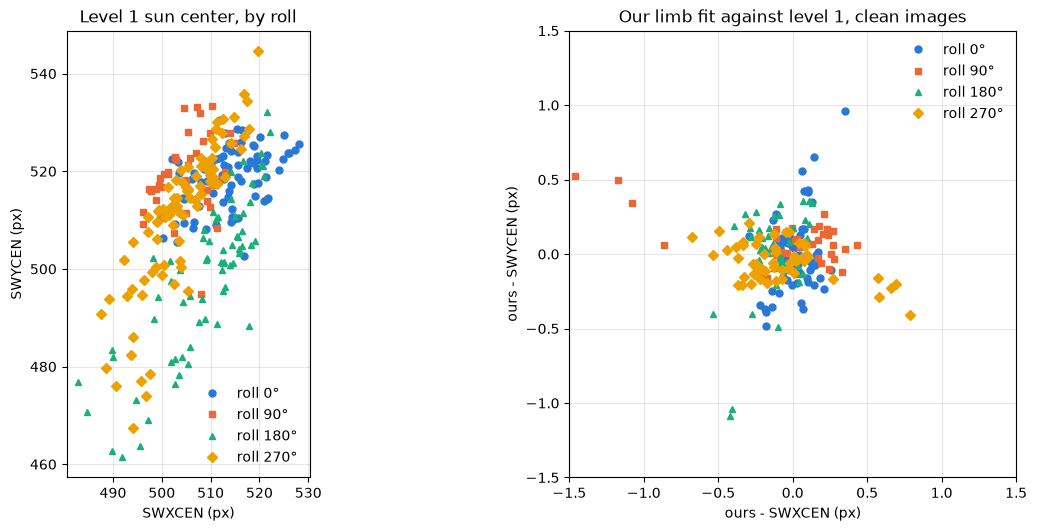

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for roll, group in centers.groupby("roll"):
    style = {"color": ROLL_COLORS[roll], "marker": ROLL_MARKERS[roll], "ls": "none", "ms": 5, "label": f"roll {roll}°"}
    axes[0].plot(group["swxcen"], group["swycen"], **style)
    good = group[group["clean"]]
    axes[1].plot(good["dx"], good["dy"], **style)
axes[0].set_xlabel("SWXCEN (px)")
axes[0].set_ylabel("SWYCEN (px)")
axes[0].set_title("Level 1 sun center, by roll")
axes[0].set_aspect("equal")
axes[1].set_xlabel("ours - SWXCEN (px)")
axes[1].set_ylabel("ours - SWYCEN (px)")
axes[1].set_title("Our limb fit against level 1, clean images")
axes[1].set_xlim(-1.5, 1.5)
axes[1].set_ylim(-1.5, 1.5)
axes[1].set_aspect("equal")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend(frameon=False)
plt.show()

On the clean images our center is the pipeline's to a median of about 0.1 pixel, all within 2 pixels; the outliers are
damaged images (lost packets leave the bottom of the image grey, half the limb is missing). The limb at 17.4 nm sits
about 2 pixels outside the photospheric radius, as expected from the corona.

## 11. Reed-Solomon correction

Do the damaged images come back with `correct_errors=True`?

In [30]:
corrected = defaultdict(dict)
for path in sorted(CADU_DIR.glob("*.cadu")):
    for _, packet in iter_packets(path, correct_errors=True):
        if packet_apid(packet) == APID and kind(packet) == "image":
            copies = corrected[stamp(packet[6:], 1)]
            count = packet_sequence_count(packet)
            if count not in copies or (crc_ok(packet) and not crc_ok(copies[count])):
                copies[count] = packet
clean_corrected = sum(is_clean([c[n] for n in sequence_order(list(c))]) for c in corrected.values())
print(f"clean images: {len(clean_keys)} as is, {clean_corrected} with Reed-Solomon correction")

clean images: 225 as is, 225 with Reed-Solomon correction


No: the correction drops the frames it can't correct, and the demuxer then merges the packets around the hole, so it
gains nothing for images.

## Conclusion

Every byte of APID 20 has a meaning now, and **none of it is a sun center or a pointing offset**:

- **Packets.** Image packets (an 8 byte header `01` + end of acquisition + `00`, data, CRC-16), PUS 5/1 event 300
  reports (one per image taken, every 110 s; the "2 random bytes" are their CRC) and PUS 1/1 + 1/7 telecommand
  verification reports (commands to SWAP).
- **Time.** The stamps are the tick of the other APIDs. Bytes 8-13 of the first packet are the start of acquisition,
  which is the archive's `DATE-OBS`; the end is 13.9 s later. The "0.256 s per second" was a misread field.
- **JPEG.** Cut at `payload[8:-2]` (and `[92:-2]` for the first packet) the images decode without a warning; satdump
  loses 6 bytes and keeps a CRC byte per packet. The stream is standard libjpeg (quality 100, progressive, restart
  markers), with no comments, no extra segments and only buffer leftovers after the EOI.
- **Metadata.** It is SWAP's image header, keyword for keyword the SWAP part of the level 0 FITS header: three time
  stamps, observation and capture mode, `LANG_ROT`, `PAV_ROT0/1`, exposure, window, the detector offsets
  (`PGA_OFFS = 59`, `HASBLACK = 4`, `HASOFFST = 11`), recoding, compression, `PN`, `SIZCOMPI` and the JPEG length.
- **Pixel values.** `RECODE_TABLE[np.flipud(jpeg)]` gives the level 0 DN (98.7 % exact).
- **Sun center.** Not in APID 20 and not in level 0. The pipeline fits it to the limb, and the limb fit here reproduces
  the level 1 `SWXCEN/SWYCEN` to about 0.1 pixel on clean images. So the offsets for calibrating our images can be
  computed from the images themselves; the rotation is the roll from `LANG_ROT` plus the -0.3 degree mount offset and
  `SOLAR_EP` of the pipeline.

The README and `extract_images.py` have been updated with this: the extractor cuts the packets as in section 4, names
the images after the start of acquisition, and with `--process` turns them north up and centers the sun with this limb fit.